# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhammad Fasya Atthaya Rosyada | 5054251006 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

***Kode dijalankan menggunakan Google Colab**

**Link Deployment:**

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device yang digunakan: {device}")

Device yang digunakan: cuda


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.
folder_path = '/content/drive/MyDrive/Dataset/ML-DL2'

train_df = pd.read_csv(folder_path + '/fashion-mnist_train.csv')
test_df = pd.read_csv(folder_path + '/fashion-mnist_test.csv')

print(f"Ukuran data train: {train_df.shape}")
print(f"Ukuran data test: {test_df.shape}")

Ukuran data train: (60000, 785)
Ukuran data test: (10000, 785)


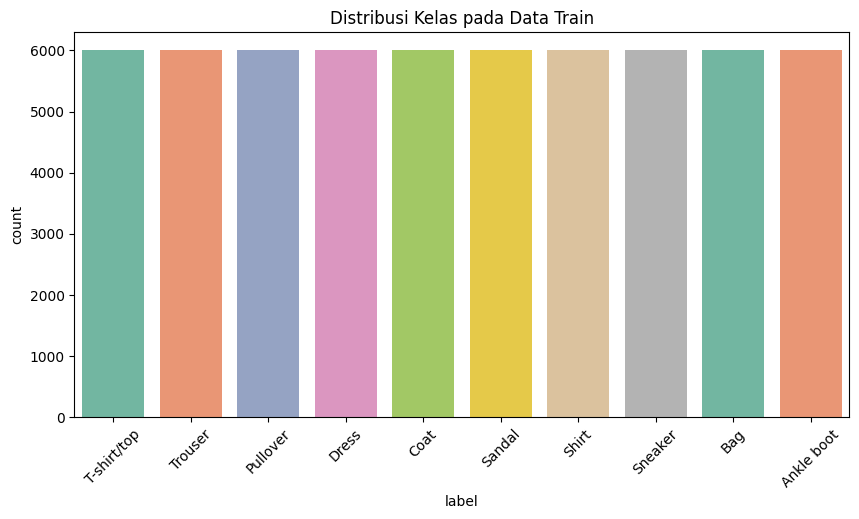

In [8]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.
labels_map = {
    0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
    5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'
}

plt.figure(figsize=(10, 5))
sns.countplot(data=train_df, x='label', hue='label', palette='Set2', legend=False)
plt.xticks(ticks=range(10), labels=[labels_map[i] for i in range(10)], rotation=45)
plt.title("Distribusi Kelas pada Data Train")
plt.show()

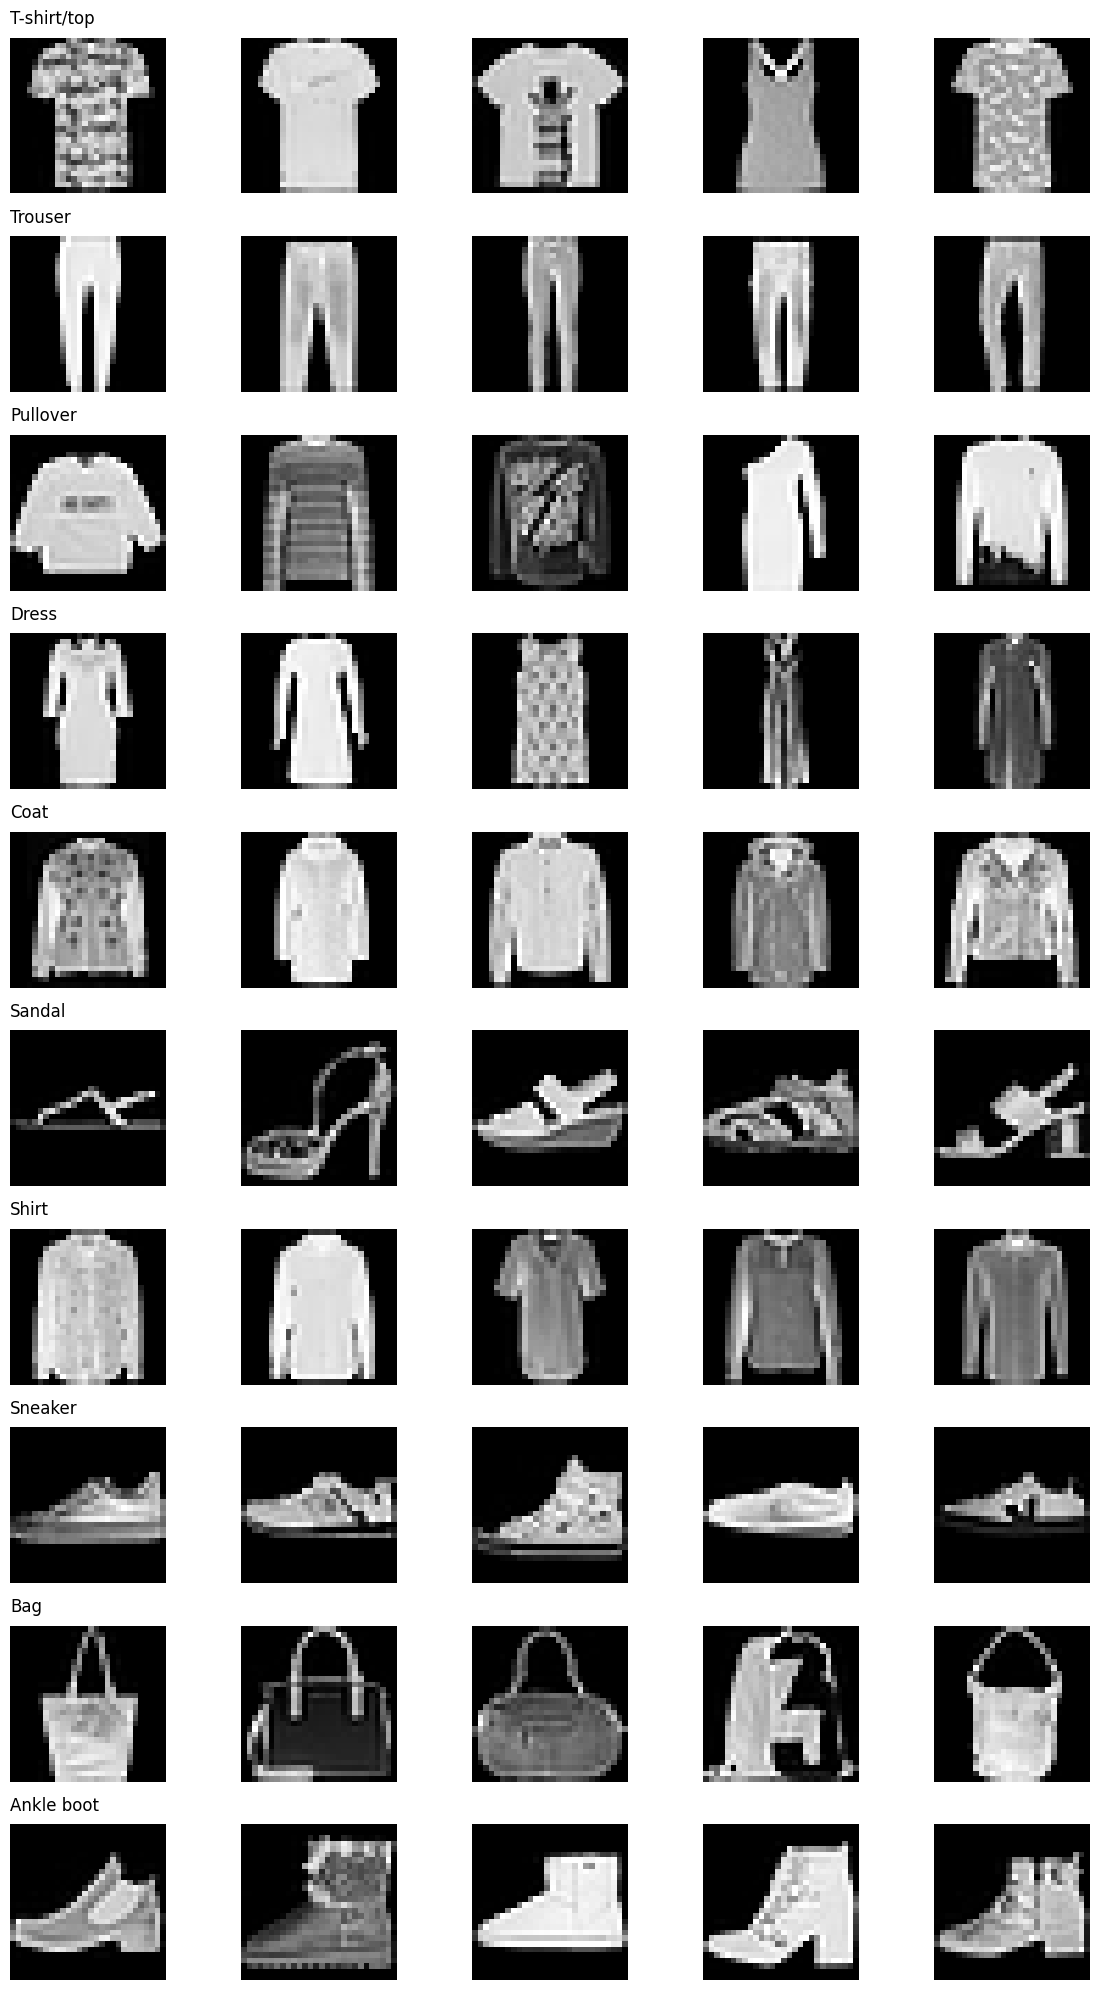

In [9]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?
fig, axes = plt.subplots(10, 5, figsize=(12, 20))
for i in range(10):
    class_imgs = train_df[train_df['label'] == i].iloc[:5, 1:].values
    for j in range(5):
        img = class_imgs[j].reshape(28, 28)
        axes[i, j].imshow(img, cmap='gray')
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(labels_map[i], loc='left', pad=10)
plt.tight_layout()
plt.show()

# Kelas yang kayak mirip-mirip gitu visualnya adalah Shirt, T-shirt/top, Pullover, dan Coat.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [10]:
# Cek missing values
print(f"Missing values pada data train: {train_df.isnull().sum().sum()}")
print(f"Missing values pada data test: {test_df.isnull().sum().sum()}")

Missing values pada data train: 0
Missing values pada data test: 0


# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [11]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
X_train_full = train_df.drop('label', axis=1).values
y_train_full = train_df['label'].values

X_test_final = test_df.drop('label', axis=1).values
y_test_final = test_df['label'].values

In [12]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
X_train_full = X_train_full / 255.0
X_test_final = X_test_final / 255.0

In [13]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, stratify=y_train_full, random_state=42
)
print(f"Jumlah Train set: {X_train.shape[0]}, Validation set: {X_val.shape[0]}")

Jumlah Train set: 54000, Validation set: 6000


In [14]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).
X_train_t = torch.tensor(X_train, dtype=torch.float32).view(-1, 1, 28, 28)
y_train_t = torch.tensor(y_train, dtype=torch.long)

X_val_t = torch.tensor(X_val, dtype=torch.float32).view(-1, 1, 28, 28)
y_val_t = torch.tensor(y_val, dtype=torch.long)

X_test_t = torch.tensor(X_test_final, dtype=torch.float32).view(-1, 1, 28, 28)
y_test_t = torch.tensor(y_test_final, dtype=torch.long)

batch_size = 64
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)

# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [15]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).
class ANNModel(nn.Module):
    def __init__(self):
        super(ANNModel, self).__init__()
        self.flatten = nn.Flatten()
        self.network = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.network(x)

model_ann = ANNModel().to(device)
print(model_ann)
print("Jumlah parameter:", sum(p.numel() for p in model_ann.parameters()))

ANNModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [16]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.
def train_and_evaluate(model, train_loader, val_loader, epochs=15, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * X_batch.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == y_batch).sum().item()
            total += y_batch.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        model.eval()
        val_loss_run, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)

                val_loss_run += loss.item() * X_batch.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == y_batch).sum().item()
                val_total += y_batch.size(0)

        val_loss = val_loss_run / val_total
        val_acc = val_correct / val_total

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        print(f"Epoch {epoch+1:02}/{epochs} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")

    return history

print("Melatih Model ANN...")
history_ann = train_and_evaluate(model_ann, train_loader, val_loader, epochs=15)

Melatih Model ANN...
Epoch 01/15 | Train Loss: 0.5434, Acc: 0.8061 | Val Loss: 0.4401, Acc: 0.8382
Epoch 02/15 | Train Loss: 0.3832, Acc: 0.8591 | Val Loss: 0.3651, Acc: 0.8637
Epoch 03/15 | Train Loss: 0.3404, Acc: 0.8758 | Val Loss: 0.3624, Acc: 0.8677
Epoch 04/15 | Train Loss: 0.3178, Acc: 0.8841 | Val Loss: 0.3246, Acc: 0.8808
Epoch 05/15 | Train Loss: 0.2971, Acc: 0.8899 | Val Loss: 0.3326, Acc: 0.8805
Epoch 06/15 | Train Loss: 0.2818, Acc: 0.8960 | Val Loss: 0.3182, Acc: 0.8862
Epoch 07/15 | Train Loss: 0.2676, Acc: 0.9006 | Val Loss: 0.3210, Acc: 0.8825
Epoch 08/15 | Train Loss: 0.2559, Acc: 0.9054 | Val Loss: 0.3188, Acc: 0.8860
Epoch 09/15 | Train Loss: 0.2457, Acc: 0.9072 | Val Loss: 0.3248, Acc: 0.8868
Epoch 10/15 | Train Loss: 0.2339, Acc: 0.9116 | Val Loss: 0.3201, Acc: 0.8793
Epoch 11/15 | Train Loss: 0.2255, Acc: 0.9148 | Val Loss: 0.3434, Acc: 0.8842
Epoch 12/15 | Train Loss: 0.2178, Acc: 0.9177 | Val Loss: 0.3226, Acc: 0.8893
Epoch 13/15 | Train Loss: 0.2093, Acc: 0.92

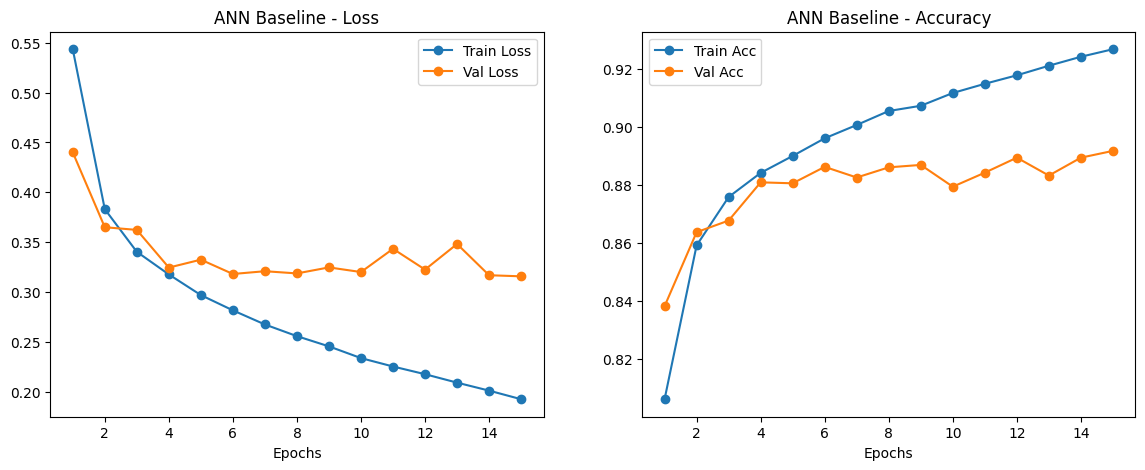

In [17]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.
def plot_learning_curve(history, title="Learning Curve"):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))

    ax[0].plot(epochs, history['train_loss'], label='Train Loss', marker='o')
    ax[0].plot(epochs, history['val_loss'], label='Val Loss', marker='o')
    ax[0].set_title(f'{title} - Loss')
    ax[0].set_xlabel('Epochs')
    ax[0].legend()

    ax[1].plot(epochs, history['train_acc'], label='Train Acc', marker='o')
    ax[1].plot(epochs, history['val_acc'], label='Val Acc', marker='o')
    ax[1].set_title(f'{title} - Accuracy')
    ax[1].set_xlabel('Epochs')
    ax[1].legend()

    plt.show()

plot_learning_curve(history_ann, "ANN Baseline")

In [18]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.
def predict_test(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            outputs = model(X_batch)
            _, preds = torch.max(outputs, 1)
            y_pred.extend(preds.cpu().numpy())
            y_true.extend(y_batch.numpy())
    return np.array(y_true), np.array(y_pred)

y_test_true, y_pred_ann = predict_test(model_ann, test_loader)

## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [19]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model_cnn_simple = SimpleCNN().to(device)
print(model_cnn_simple)
print("Jumlah parameter:", sum(p.numel() for p in model_cnn_simple.parameters()))

dummy = torch.zeros(1, 1, 28, 28).to(device)
print("Shape setelah layer konvolusi:", model_cnn_simple.features(dummy).shape)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642
Shape setelah layer konvolusi: torch.Size([1, 64, 7, 7])


Melatih Model CNN Sederhana...
Epoch 01/15 | Train Loss: 0.4830, Acc: 0.8257 | Val Loss: 0.3595, Acc: 0.8715
Epoch 02/15 | Train Loss: 0.3062, Acc: 0.8884 | Val Loss: 0.2908, Acc: 0.8980
Epoch 03/15 | Train Loss: 0.2595, Acc: 0.9050 | Val Loss: 0.2700, Acc: 0.9012
Epoch 04/15 | Train Loss: 0.2296, Acc: 0.9158 | Val Loss: 0.2444, Acc: 0.9102
Epoch 05/15 | Train Loss: 0.2027, Acc: 0.9255 | Val Loss: 0.2420, Acc: 0.9110
Epoch 06/15 | Train Loss: 0.1826, Acc: 0.9329 | Val Loss: 0.2491, Acc: 0.9105
Epoch 07/15 | Train Loss: 0.1635, Acc: 0.9399 | Val Loss: 0.2156, Acc: 0.9223
Epoch 08/15 | Train Loss: 0.1450, Acc: 0.9458 | Val Loss: 0.2191, Acc: 0.9245
Epoch 09/15 | Train Loss: 0.1296, Acc: 0.9523 | Val Loss: 0.2225, Acc: 0.9193
Epoch 10/15 | Train Loss: 0.1116, Acc: 0.9582 | Val Loss: 0.2458, Acc: 0.9182
Epoch 11/15 | Train Loss: 0.0970, Acc: 0.9639 | Val Loss: 0.2388, Acc: 0.9182
Epoch 12/15 | Train Loss: 0.0847, Acc: 0.9690 | Val Loss: 0.2437, Acc: 0.9235
Epoch 13/15 | Train Loss: 0.0719,

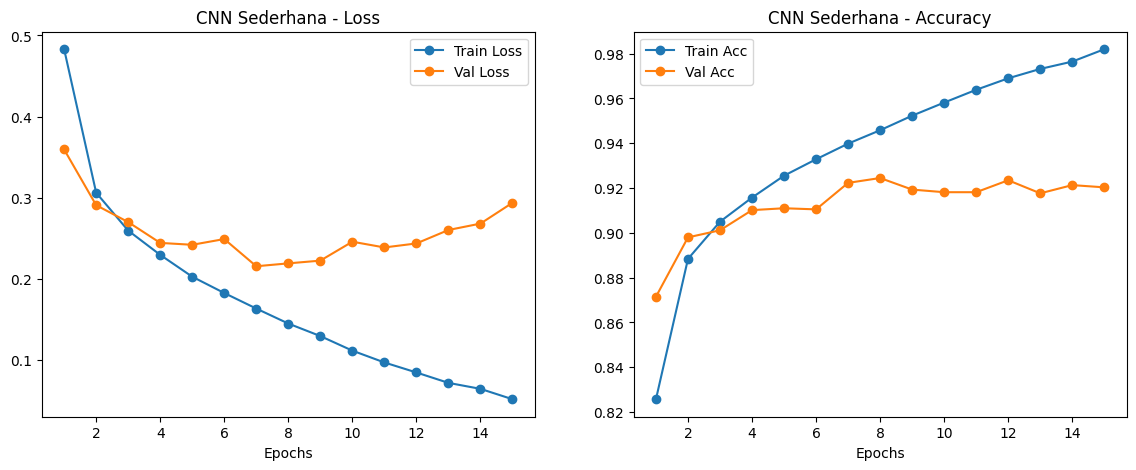

In [20]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.
print("Melatih Model CNN Sederhana...")
history_cnn_simple = train_and_evaluate(model_cnn_simple, train_loader, val_loader, epochs=15)
plot_learning_curve(history_cnn_simple, "CNN Sederhana")

In [21]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
_, y_pred_cnn_simple = predict_test(model_cnn_simple, test_loader)

## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [22]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.
class AdvancedCNN(nn.Module):
    def __init__(self):
        super(AdvancedCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.5), # Mencegah overfitting
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model_cnn_adv = AdvancedCNN().to(device)
print(model_cnn_adv)
print("Jumlah parameter:", sum(p.numel() for p in model_cnn_adv.parameters()))

AdvancedCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


Melatih Model CNN dengan BatchNorm dan Dropout...
Epoch 01/15 | Train Loss: 0.5176, Acc: 0.8144 | Val Loss: 0.3180, Acc: 0.8810
Epoch 02/15 | Train Loss: 0.3601, Acc: 0.8711 | Val Loss: 0.2787, Acc: 0.9002
Epoch 03/15 | Train Loss: 0.3136, Acc: 0.8868 | Val Loss: 0.2649, Acc: 0.9043
Epoch 04/15 | Train Loss: 0.2795, Acc: 0.8995 | Val Loss: 0.2474, Acc: 0.9087
Epoch 05/15 | Train Loss: 0.2591, Acc: 0.9050 | Val Loss: 0.2400, Acc: 0.9142
Epoch 06/15 | Train Loss: 0.2418, Acc: 0.9115 | Val Loss: 0.2350, Acc: 0.9172
Epoch 07/15 | Train Loss: 0.2253, Acc: 0.9181 | Val Loss: 0.2362, Acc: 0.9148
Epoch 08/15 | Train Loss: 0.2111, Acc: 0.9224 | Val Loss: 0.2327, Acc: 0.9183
Epoch 09/15 | Train Loss: 0.1997, Acc: 0.9274 | Val Loss: 0.2290, Acc: 0.9193
Epoch 10/15 | Train Loss: 0.1893, Acc: 0.9299 | Val Loss: 0.2328, Acc: 0.9168
Epoch 11/15 | Train Loss: 0.1778, Acc: 0.9344 | Val Loss: 0.2353, Acc: 0.9185
Epoch 12/15 | Train Loss: 0.1712, Acc: 0.9367 | Val Loss: 0.2365, Acc: 0.9248
Epoch 13/15 | 

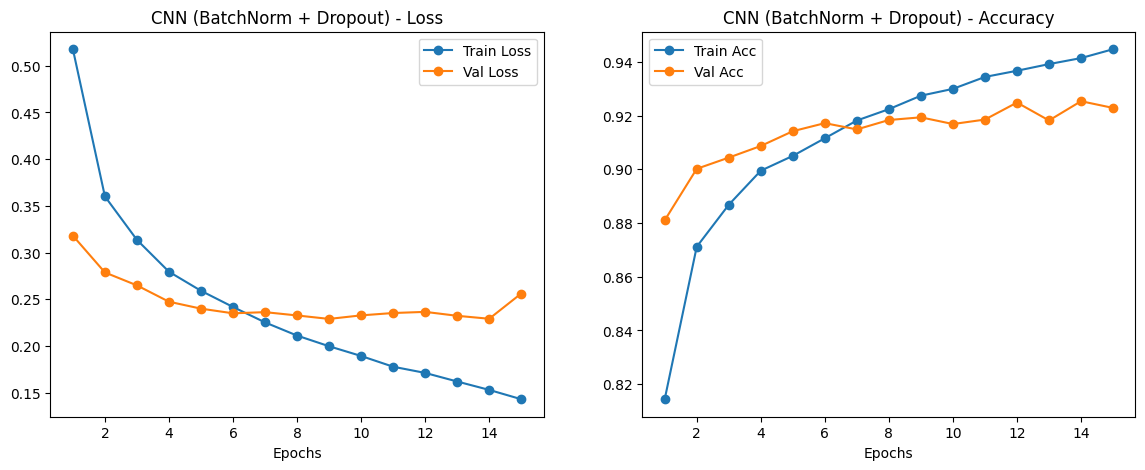

In [23]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.
print("Melatih Model CNN dengan BatchNorm dan Dropout...")
history_cnn_adv = train_and_evaluate(model_cnn_adv, train_loader, val_loader, epochs=15)
plot_learning_curve(history_cnn_adv, "CNN (BatchNorm + Dropout)")

In [24]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
_, y_pred_cnn_adv = predict_test(model_cnn_adv, test_loader)

# 4. Evaluasi Model

In [25]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.
def calc_metrics(y_true, y_pred, model_name, params):
    return {
        'Model': model_name,
        'Parameters': params,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='macro'),
        'Recall': recall_score(y_true, y_pred, average='macro'),
        'F1-Score': f1_score(y_true, y_pred, average='macro')
    }

results = [
    calc_metrics(y_test_true, y_pred_ann, "ANN Baseline", sum(p.numel() for p in model_ann.parameters())),
    calc_metrics(y_test_true, y_pred_cnn_simple, "CNN Sederhana", sum(p.numel() for p in model_cnn_simple.parameters())),
    calc_metrics(y_test_true, y_pred_cnn_adv, "CNN BN+Dropout", sum(p.numel() for p in model_cnn_adv.parameters()))
]

results_df = pd.DataFrame(results)
display(results_df)

,Model,Parameters,Accuracy,Precision,Recall,F1-Score
0,ANN Baseline,235146,0.8934,0.895193,0.8934,0.893368
1,CNN Sederhana,421642,0.9263,0.927380,0.9263,0.926650
2,CNN BN+Dropout,421834,0.9299,0.931283,0.9299,0.930298


In [26]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.
print("Classification Report untuk Model Terbaik (CNN BN+Dropout):")
print(classification_report(y_test_true, y_pred_cnn_adv, target_names=[labels_map[i] for i in range(10)]))

Classification Report untuk Model Terbaik (CNN BN+Dropout):
              precision    recall  f1-score   support

 T-shirt/top       0.87      0.90      0.88      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.93      0.85      0.89      1000
       Dress       0.94      0.93      0.93      1000
        Coat       0.90      0.90      0.90      1000
      Sandal       0.99      0.98      0.99      1000
       Shirt       0.77      0.82      0.79      1000
     Sneaker       0.97      0.96      0.96      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.97      0.98      0.97      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



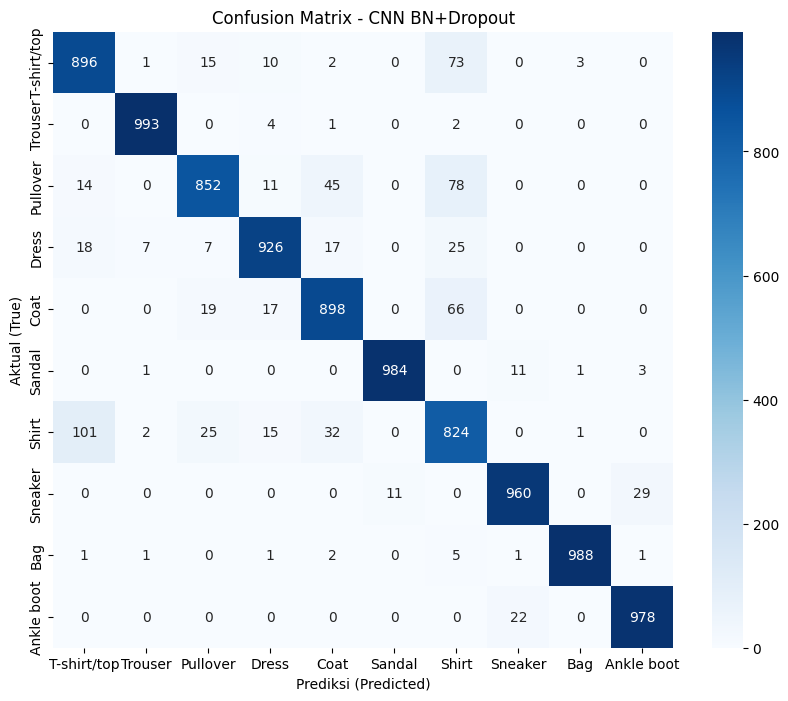

In [27]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?
cm = confusion_matrix(y_test_true, y_pred_cnn_adv)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[labels_map[i] for i in range(10)],
            yticklabels=[labels_map[i] for i in range(10)])
plt.xlabel('Prediksi (Predicted)')
plt.ylabel('Aktual (True)')
plt.title('Confusion Matrix - CNN BN+Dropout')
plt.show()
# Yang sering ketuker itu Shirt vs T-shirt/top

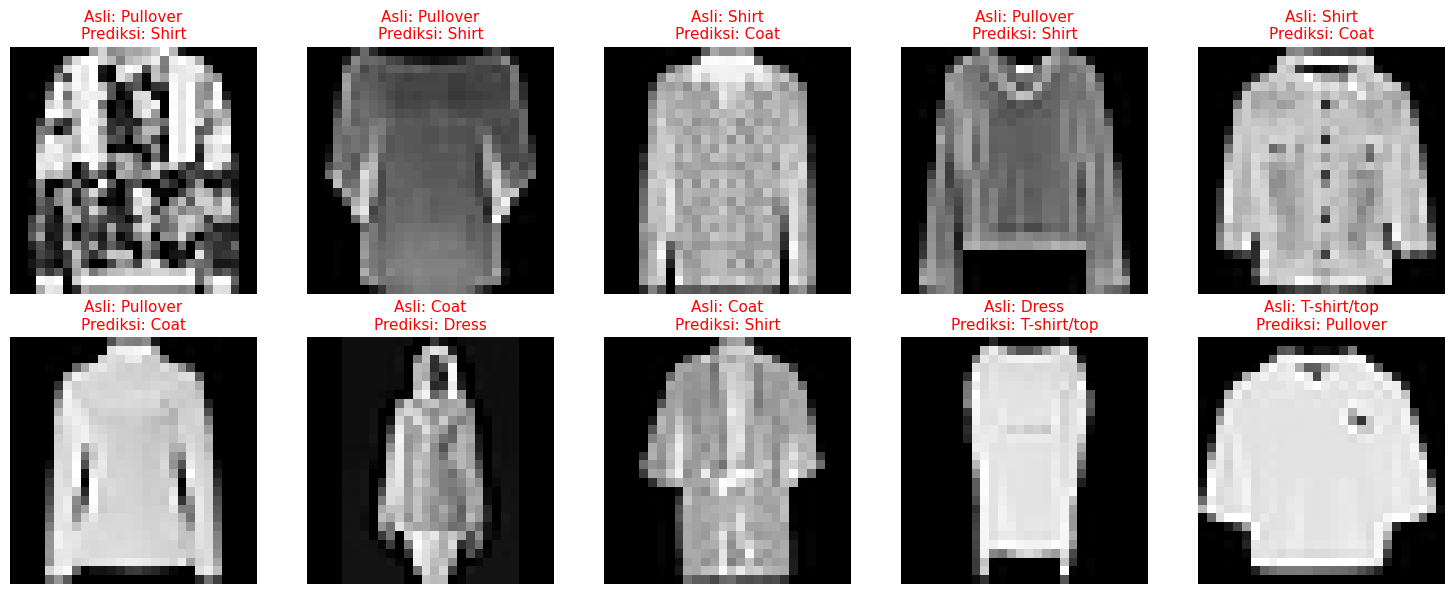

In [28]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.
errors = np.where(y_pred_cnn_adv != y_test_true)[0]
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, idx in enumerate(errors[:10]):
    img = X_test_final[idx].reshape(28, 28)
    true_label = labels_map[y_test_true[idx]]
    pred_label = labels_map[y_pred_cnn_adv[idx]]

    ax = axes[i // 5, i % 5]
    ax.imshow(img, cmap='gray')
    ax.set_title(f"Asli: {true_label}\nPrediksi: {pred_label}", color='red', fontsize=11)
    ax.axis('off')

plt.tight_layout()
plt.show()

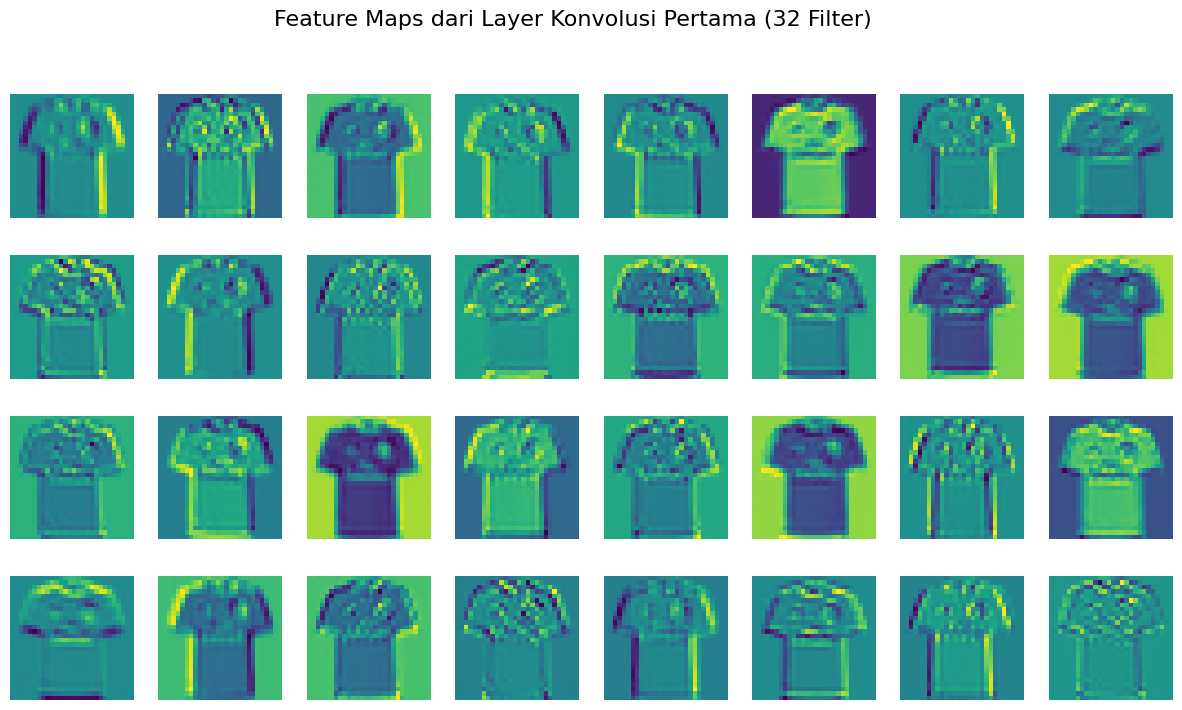

In [29]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?
sample_img = X_test_t[0].unsqueeze(0).to(device)
first_conv_layer = model_cnn_adv.features[0]
feature_maps = first_conv_layer(sample_img).detach().cpu().numpy()

fig, axes = plt.subplots(4, 8, figsize=(15, 8))
fig.suptitle('Feature Maps dari Layer Konvolusi Pertama (32 Filter)', fontsize=16)

for i in range(32):
    ax = axes[i // 8, i % 8]
    ax.imshow(feature_maps[0, i, :, :], cmap='viridis')
    ax.axis('off')

plt.show()
# Beberapa pola yang ditangkep itu kayak siluet, garis tepi, tekstur, area negatif, dll (?)

In [30]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.
torch.save(model_cnn_adv.state_dict(), "model_terbaik_cnn.pth")
print("Model terbaik berhasil disimpan!")

Model terbaik berhasil disimpan!


# 5. Analisis

*   **Performa Model:**
    *   **ANN Baseline** secara umum memberikan performa terendah (akurasi lebih rendah) karena ia meratakan (*flatten*) seluruh piksel gambar di awal. Hal ini menghilangkan informasi spasial dan relasi dua dimensi (seperti bentuk atau tekstur) yang penting untuk mengenali pakaian.
    *   **CNN Sederhana** menunjukkan peningkatan performa yang signifikan dibandingkan ANN. Filter konvolusi pada CNN mampu mendeteksi pola fitur tingkat rendah hingga tinggi (seperti garis tepi kerah atau tekstur sepatu) sebelum diumpankan ke *classifier*, menjadikannya lebih optimal untuk data citra.
    *   **CNN dengan Batch Normalization dan Dropout (CNN BN+Dropout)** menghasilkan performa terbaik. Model ini tidak hanya mencapai akurasi tertinggi, tetapi juga memiliki *learning curve* yang paling stabil.
*   **Pengaruh Batch Normalization dan Dropout:**
    *   *Batch Normalization* menormalkan distribusi input pada setiap layer, yang secara signifikan mempercepat proses konvergensi selama *training* dan mengurangi sensitivitas model terhadap inisialisasi bobot awal.
    *   *Dropout* (dengan proporsi 0.5 sebelum layer *output*) terbukti sangat efektif mengurangi *overfitting*. Hal ini terlihat dari mengecilnya *gap* (selisih) antara metrik akurasi data *train* dan *validation* dibandingkan model CNN sederhana.
*   **Analisis Kelas yang Sulit Dibedakan:**
    Berdasarkan *Confusion Matrix*, kelas-kelas yang paling sering salah diprediksi (tertukar) oleh model adalah antara **"Shirt" (Kemeja), "T-shirt/top" (Kaos)**, **"Pullover" dan "Coat" (Mantel)**. Kesalahan ini wajar terjadi karena kelas-kelas tersebut memiliki kemiripan bentuk siluet dasar, kerah, dan panjang lengan yang sulit dibedakan pada resolusi gambar yang sangat rendah (28x28 piksel).

# 6. Kesimpulan dan Saran

### Kesimpulan
Eksperimen ini membuktikan bahwa arsitektur Convolutional Neural Network (CNN) jauh lebih unggul dibandingkan Artificial Neural Network (ANN) standar dalam tugas klasifikasi citra seperti Fashion-MNIST. Pemrosesan hierarkis melalui layer konvolusi dan *pooling* memungkinkan CNN mengekstraksi fitur spasial secara efektif. Lebih jauh lagi, penambahan teknik regularisasi (*Dropout*) dan stabilisasi (*Batch Normalization*) adalah strategi arsitektur yang sangat krusial untuk menghasilkan model yang tidak hanya akurat di data latih, tetapi juga mampu melakukan generalisasi dengan baik pada data uji yang belum pernah dilihat sebelumnya.

### Saran
Untuk eksperimen dan pengembangan model selanjutnya, beberapa hal berikut dapat direkomendasikan:
1.  **Data Augmentation:** Menerapkan transformasi ringan pada data *training* (seperti rotasi kecil, pergeseran horizontal/vertikal, atau *random horizontal flip*) untuk memperbanyak variasi data dan membantu model belajar membedakan kelas-kelas yang mirip (seperti *Shirt* vs *T-shirt*).
2.  **Learning Rate Scheduler:** Menggunakan *scheduler* (seperti `ReduceLROnPlateau`) untuk menurunkan *learning rate* secara otomatis ketika performa validasi mulai stagnan, sehingga model dapat mencapai titik konvergensi yang lebih optimal.
3.  **Eksplorasi Arsitektur Tingkat Lanjut:** Jika komputasi memungkinkan, mencoba arsitektur CNN modern yang lebih dalam seperti ResNet (Residual Networks) versi ringan untuk mengevaluasi apakah penambahan layer *residual* dapat meningkatkan akurasi lebih jauh tanpa *vanishing gradient*.